In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Activation, ReLU
from tensorflow.keras.layers import BatchNormalization, Conv2DTranspose, Concatenate
from tensorflow.keras.models import Model, Sequential

#1. definie convolution_operation

In [ ]:
def convolution_operation(entered_input, filters=64):
    # Taking first input and implementing the first conv block
    conv1 = Conv2D(filters, kernel_size = (3,3), padding = "same")(entered_input)
    batch_norm1 = BatchNormalization()(conv1)
    act1 = ReLU()(batch_norm1)

    # Taking first input and implementing the second conv block
    conv2 = Conv2D(filters, kernel_size = (3,3), padding = "same")(act1)
    batch_norm2 = BatchNormalization()(conv2)
    act2 = ReLU()(batch_norm2)

    return act2

In [ ]:
def encoder(entered_input, filters=64):
    # Collect the start and end of each sub-block for normal pass and skip connections
    enc1 = convolution_operation(entered_input, filters)
    MaxPool1 = MaxPooling2D(strides = (2,2))(enc1)
    return enc1, MaxPool1

In [ ]:
def decoder(entered_input, skip, filters=64):
    # Upsampling and concatenating the essential features
    Upsample = Conv2DTranspose(filters, (2, 2), strides=2, padding="same")(entered_input)
    Connect_Skip = Concatenate()([Upsample, skip])
    out = convolution_operation(Connect_Skip, filters)
    return out

In [ ]:
def U_Net(Image_Size):
    # Take the image size and shape
    input1 = Input(Image_Size)

    # Construct the encoder blocks
    skip1, encoder_1 = encoder(input1, 64)
    skip2, encoder_2 = encoder(encoder_1, 64*2)
    skip3, encoder_3 = encoder(encoder_2, 64*4)
    skip4, encoder_4 = encoder(encoder_3, 64*8)

    # Preparing the next block
    conv_block = convolution_operation(encoder_4, 64*16)

    # Construct the decoder blocks
    decoder_1 = decoder(conv_block, skip4, 64*8)
    decoder_2 = decoder(decoder_1, skip3, 64*4)
    decoder_3 = decoder(decoder_2, skip2, 64*2)
    decoder_4 = decoder(decoder_3, skip1, 64)

    out = Conv2D(1, 1, padding="same", activation="sigmoid")(decoder_4)

    model = Model(input1, out)
    return model

In [ ]:
input_shape = (160, 160, 3)
model = U_Net(input_shape)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 160, 160,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 160, 160,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 160, 160,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 160, 160,  │     36,928 │ re_lu[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 160,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 160, 160,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 80, 80,    │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 80, 80,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 80, 80,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 80, 80,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 80, 80,    │    147,584 │ re_lu_2[0][0]     │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 80, 80,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 80, 80,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 40, 40,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 40, 40,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 40, 40,    │      1,024 │ conv2d_4[0][0]  

 Total params: 31,055,297 (118.47 MB)

 Trainable params: 31,043,521 (118.42 MB)

 Non-trainable params: 11,776 (46.00 KB)

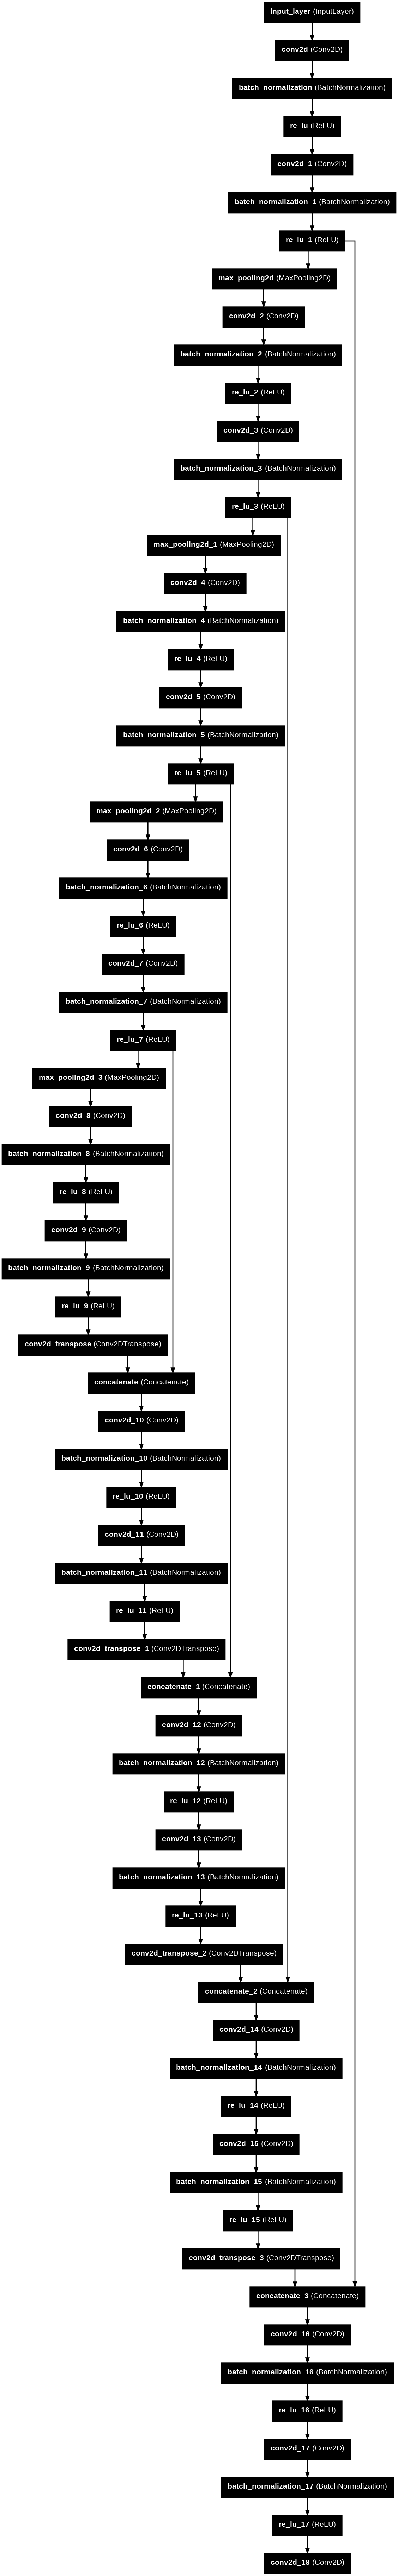

In [ ]:
tf.keras.utils.plot_model(model, "model.png", show_shapes=False, show_dtype=False, show_layer_names=True, rankdir='TB', expand_nested=False, dpi=96)

#2. Load data

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

input_dir = "/content/drive/MyDrive/SI/data_2024"
target_dir = "/content/drive/MyDrive/SI/masks_via_2024"

# Get just the filenames (without paths)
input_files = sorted([ f for f in os.listdir(input_dir) if f.endswith(".png")])
target_files = sorted([f.replace('_mask.png','.png') for f in os.listdir(target_dir) if f.endswith(".png") and not f.startswith(".")])

# Find which input files are missing in target
missing_files = [ f for f in input_files if f not in target_files]

print("Missing masks:", len(missing_files))
print(len(input_files))
print(len(target_files))
for f in missing_files:
    os.remove(input_dir+ '/'+ f)

Missing masks: 0
1024
1024


In [ ]:
import os
import numpy as np
input_dir = "/content/drive/MyDrive/SI/data_2024"
target_dir = "/content/drive/MyDrive/SI/masks_via_2024"
img_size = (160, 160)
num_classes = 2
batch_size = 8

input_img_paths_2024 = sorted(
    [
        os.path.join(input_dir, fname)
        for fname in os.listdir(input_dir)
        if fname.endswith(".png")
    ]
)
target_img_paths_2024 = sorted(
    [
        os.path.join(target_dir, fname)
        for fname in os.listdir(target_dir)
        if fname.endswith(".png") and not fname.startswith(".")
    ]
)

print("Number of samples:", len(input_img_paths_2024))
for input_path, target_path in zip(input_img_paths_2024[:10], target_img_paths_2024[:10]):
    print(input_path, "|", target_path)

Number of samples: 1024
/content/drive/MyDrive/SI/data_2024/2024-01-01T12-00-00.000Z.png | /content/drive/MyDrive/SI/masks_via_2024/2024-01-01T12-00-00.000Z_mask.png
/content/drive/MyDrive/SI/data_2024/2024-01-01T15-00-00.000Z.png | /content/drive/MyDrive/SI/masks_via_2024/2024-01-01T15-00-00.000Z_mask.png
/content/drive/MyDrive/SI/data_2024/2024-01-01T18-00-00.000Z.png | /content/drive/MyDrive/SI/masks_via_2024/2024-01-01T18-00-00.000Z_mask.png
/content/drive/MyDrive/SI/data_2024/2024-01-02T12-00-00.000Z.png | /content/drive/MyDrive/SI/masks_via_2024/2024-01-02T12-00-00.000Z_mask.png
/content/drive/MyDrive/SI/data_2024/2024-01-02T15-00-00.000Z.png | /content/drive/MyDrive/SI/masks_via_2024/2024-01-02T15-00-00.000Z_mask.png
/content/drive/MyDrive/SI/data_2024/2024-01-02T18-00-00.000Z.png | /content/drive/MyDrive/SI/masks_via_2024/2024-01-02T18-00-00.000Z_mask.png
/content/drive/MyDrive/SI/data_2024/2024-01-03T12-00-00.000Z.png | /content/drive/MyDrive/SI/masks_via_2024/2024-01-03T12-00

In [ ]:
import os
import numpy as np
input_dir = "/content/drive/MyDrive/SI/data_2023"
target_dir = "/content/drive/MyDrive/SI/mask_via_2023"
img_size = (160, 160)
num_classes = 2
batch_size = 8

input_img_paths_2023 = sorted(
    [
        os.path.join(input_dir, fname)
        for fname in os.listdir(input_dir)
        if fname.endswith(".png")
    ]
)
target_img_paths_2023 = sorted(
    [
        os.path.join(target_dir, fname)
        for fname in os.listdir(target_dir)
        if fname.endswith(".png") and not fname.startswith(".")
    ]
)

print("Number of samples:", len(input_img_paths_2023))
for input_path, target_path in zip(input_img_paths_2023[:10], target_img_paths_2023[:10]):
    print(input_path, "|", target_path)

Number of samples: 2552
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T03-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T03-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T06-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T06-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T09-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T09-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T12-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T12-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T15-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T15-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T18-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T18-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T21-00-00.000Z.png 

In [ ]:
[4,5,3,6] + [32,2]

[4, 5, 3, 6, 32, 2]

In [ ]:
input_img_paths_all = input_img_paths_2023 + input_img_paths_2024
target_img_paths_all = target_img_paths_2023 + target_img_paths_2024
for input_path, target_path in zip(input_img_paths_all[:5] + input_img_paths_all[-6:-1], target_img_paths_all[:5] + target_img_paths_all[-6:-1]):
    print(input_path, "|", target_path)
print(len(input_img_paths_all))
print(len(target_img_paths_all))

/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T03-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T03-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T06-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T06-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T09-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T09-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T12-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T12-00-00.000Z.png
/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T15-00-00.000Z.png | /content/drive/MyDrive/SI/mask_via_2023/mask_prod_2023-01-01T15-00-00.000Z.png
/content/drive/MyDrive/SI/data_2024/2024-12-06T12-00-00.000Z.png | /content/drive/MyDrive/SI/masks_via_2024/2024-12-06T12-00-00.000Z_mask.png
/content/drive/MyDrive/SI/data_2024/2024-12-06T15-00-00.000Z.png | /content/drive/MyDrive/SI/masks_via_

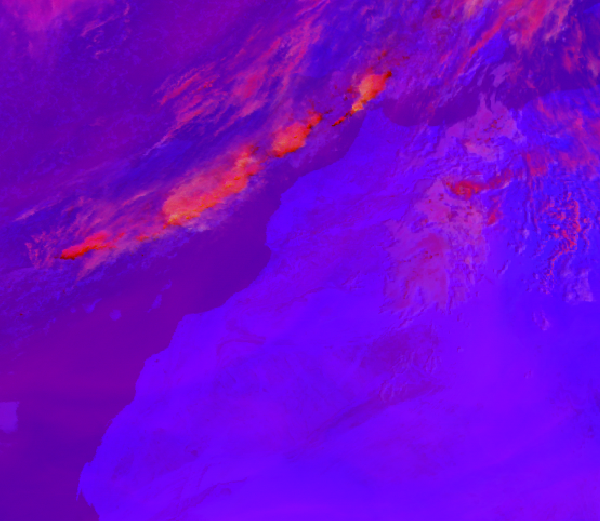

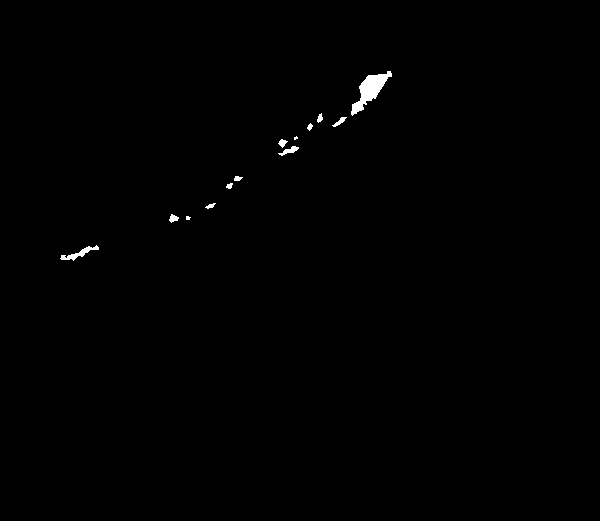

In [ ]:
from IPython.display import Image, display
from tensorflow.keras.preprocessing.image import load_img
import PIL
from PIL import ImageOps

# Display input image #7
display(Image(filename=input_img_paths_all[9]))

# Display auto-contrast version of corresponding target (per-pixel categories)
img = PIL.ImageOps.autocontrast(load_img(target_img_paths_all[9]))
display(img)


#2.2 Data generator

In [ ]:
from tensorflow import keras
import numpy as np
from tensorflow.keras.preprocessing.image import load_img


class SegmentationDataset(keras.utils.Sequence):
    """Helper to iterate over the data (as Numpy arrays)."""

    def __init__(self, batch_size, img_size, input_img_paths, target_img_paths):
        self.batch_size = batch_size
        self.img_size = img_size
        self.input_img_paths = input_img_paths
        self.target_img_paths = target_img_paths

    def __len__(self):
        return len(self.target_img_paths) // self.batch_size

    def __getitem__(self, idx):
        """Returns tuple (input, target) correspond to batch #idx."""
        i = idx * self.batch_size
        batch_input_img_paths = self.input_img_paths[i : i + self.batch_size]
        batch_target_img_paths = self.target_img_paths[i : i + self.batch_size]
        x = np.zeros((self.batch_size,) + self.img_size + (3,), dtype="float32")
        for j, path in enumerate(batch_input_img_paths):
            img = load_img(path, target_size=self.img_size)
            x[j] = img
        y = np.zeros((self.batch_size,) + self.img_size + (1,), dtype="uint8")
        for j, path in enumerate(batch_target_img_paths):
            img = load_img(path, target_size=self.img_size, color_mode="grayscale")
            y[j] = np.expand_dims(img, 2)
            # Ground truth labels are 1, 2, 3. Subtract one to make them 0, 1, 2:
            y[j] -= 1
        return x, y

In [ ]:
from tensorflow import keras
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

class SegmentationDataset(keras.utils.Sequence):
    """Keras Sequence for binary segmentation tasks."""

    def __init__(self, batch_size, img_size, input_img_paths, target_img_paths,**kwargs):
        super().__init__(**kwargs)
        self.batch_size = batch_size
        self.img_size = img_size
        self.input_img_paths = input_img_paths
        self.target_img_paths = target_img_paths

    def __len__(self):
        return len(self.target_img_paths) // self.batch_size

    def __getitem__(self, idx):
        i = idx * self.batch_size
        batch_input_img_paths = self.input_img_paths[i: i + self.batch_size]
        batch_target_img_paths = self.target_img_paths[i: i + self.batch_size]

        # Inputs
        x = np.zeros((self.batch_size,) + self.img_size + (3,), dtype="float32")
        for j, path in enumerate(batch_input_img_paths):
            img = load_img(path, target_size=self.img_size)
            img_array = img_to_array(img) / 255.0  # Normalize to [0, 1]
            x[j] = img_array

        # Targets
        y = np.zeros((self.batch_size,) + self.img_size + (1,), dtype="float32")
        for j, path in enumerate(batch_target_img_paths):
            img = load_img(path, target_size=self.img_size, color_mode="grayscale")
            img_array = img_to_array(img) / 255.0  # Normalize 255 → 1
            y[j] = img_array  # shape (H, W, 1), values 0.0 or 1.0

        return x, y


In [ ]:
import random
# Split our img paths into a training and a validation set
val_samples = int(len(input_img_paths_all)*0.2)
random.Random(1337).shuffle(input_img_paths_all)
random.Random(1337).shuffle(target_img_paths_all)
train_input_img_paths = input_img_paths_all[:-val_samples]
train_target_img_paths = target_img_paths_all[:-val_samples]
val_input_img_paths = input_img_paths_all[-val_samples:]
val_target_img_paths = target_img_paths_all[-val_samples:]
print(train_input_img_paths)
# Instantiate data Sequences for each split
train_gen = SegmentationDataset(
    batch_size, img_size, train_input_img_paths, train_target_img_paths
)
val_gen = SegmentationDataset(batch_size, img_size, val_input_img_paths, val_target_img_paths)

['/content/drive/MyDrive/SI/data_2023/prod_2023-05-15T09-00-00.000Z.png', '/content/drive/MyDrive/SI/data_2023/prod_2023-03-30T15-00-00.000Z.png', '/content/drive/MyDrive/SI/data_2023/prod_2023-10-04T06-00-00.000Z.png', '/content/drive/MyDrive/SI/data_2024/2024-07-06T15-00-00.000Z.png', '/content/drive/MyDrive/SI/data_2023/prod_2023-05-10T06-00-00.000Z.png', '/content/drive/MyDrive/SI/data_2023/prod_2023-05-15T03-00-00.000Z.png', '/content/drive/MyDrive/SI/data_2023/prod_2023-05-16T06-00-00.000Z.png', '/content/drive/MyDrive/SI/data_2023/prod_2023-07-07T18-00-00.000Z.png', '/content/drive/MyDrive/SI/data_2023/prod_2023-12-10T18-00-00.000Z.png', '/content/drive/MyDrive/SI/data_2024/2024-07-02T18-00-00.000Z.png', '/content/drive/MyDrive/SI/data_2024/2024-09-30T18-00-00.000Z.png', '/content/drive/MyDrive/SI/data_2023/prod_2023-08-30T21-00-00.000Z.png', '/content/drive/MyDrive/SI/data_2023/prod_2023-12-06T03-00-00.000Z.png', '/content/drive/MyDrive/SI/data_2023/prod_2023-10-09T09-00-00.000

In [ ]:
import random
import os

# Set split ratios
val_ratio = 0.15
test_ratio = 0.15  # 10% for test, adjust as needed

# Shuffle with fixed seed for reproducibility
random.seed(1337)
combined = list(zip(input_img_paths_all, target_img_paths_all))
random.shuffle(combined)
input_img_paths, target_img_paths = zip(*combined)

# Calculate sizes
total_samples = len(input_img_paths)
val_samples = int(total_samples * val_ratio)
test_samples = int(total_samples * test_ratio)

# Split into train / val / test
train_input_img_paths = input_img_paths[:-(val_samples + test_samples)]
train_target_img_paths = target_img_paths[:-(val_samples + test_samples)]

val_input_img_paths = input_img_paths[-(val_samples + test_samples):-test_samples]
val_target_img_paths = target_img_paths[-(val_samples + test_samples):-test_samples]

test_input_img_paths = input_img_paths[-test_samples:]
test_target_img_paths = target_img_paths[-test_samples:]


print(f"Train samples: {len(train_input_img_paths)}")
print(f"Val samples:   {len(val_input_img_paths)}")
print(f"Test samples:  {len(test_input_img_paths)}")

# Instantiate data generators
train_gen = SegmentationDataset(batch_size, img_size, train_input_img_paths, train_target_img_paths)
val_gen = SegmentationDataset(batch_size, img_size, val_input_img_paths, val_target_img_paths)
test_gen = SegmentationDataset(batch_size, img_size, test_input_img_paths, test_target_img_paths)


Train samples: 2504
Val samples:   536
Test samples:  536


## Train the model Unet

In [ ]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import MeanIoU
from tensorflow.keras.losses import binary_crossentropy
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger
import tensorflow.keras.backend as K
import os

# Dice Coefficient implementation
def dice_coef(y_true, y_pred, smooth=1):
    intersection = K.sum(y_true * y_pred, axis=[1,2,3])
    union = K.sum(y_true, axis=[1,2,3]) + K.sum(y_pred, axis=[1,2,3])
    return K.mean((2. * intersection + smooth)/(union + smooth), axis=0)

def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)

# Combined loss (binary crossentropy + dice)
def combined_loss(y_true, y_pred):
    return binary_crossentropy(y_true, y_pred) + dice_loss(y_true, y_pred)

# Model compilation
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=combined_loss,  # You can also use just 'binary_crossentropy' here
    metrics=['accuracy', dice_coef, MeanIoU(num_classes=2)]
)

# Callbacks setup
os.makedirs('/content/drive/MyDrive/SI/callbacks', exist_ok=True)

callbacks = [
    ModelCheckpoint(
        '/content/drive/MyDrive/SI/callbacks/model_all_best.keras',
        monitor='val_dice_coef',
        mode='max',
        save_best_only=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath='/content/drive/MyDrive/SI/callbacks/model_all_last_model.keras',
        save_best_only=False,  # Saves the final model, even if not the best
        verbose=1
    ),

    EarlyStopping(
        monitor='val_dice_coef',
        patience=20,
        mode='max',
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.1,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    CSVLogger('/content/drive/MyDrive/SI/callbacks/training_log_all.csv')
]


In [ ]:
# Train the model, doing validation at the end of each epoch.
epochs = 40
model.fit(train_gen, epochs=epochs, validation_data=val_gen, callbacks=callbacks)

Epoch 1/40
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8363 - dice_coef: 0.0244 - loss: 1.4099 - mean_io_u: 0.5051
Epoch 1: val_dice_coef improved from -inf to 0.01350, saving model to /content/drive/MyDrive/SI/callbacks/model_all_best.keras

Epoch 1: saving model to /content/drive/MyDrive/SI/callbacks/model_all_last_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 2345s 7s/step - accuracy: 0.8367 - dice_coef: 0.0244 - loss: 1.4094 - mean_io_u: 0.5051 - val_accuracy: 0.9915 - val_dice_coef: 0.0135 - val_loss: 1.1734 - val_mean_io_u: 0.4958 - learning_rate: 1.0000e-04
Epoch 2/40
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.9886 - dice_coef: 0.0370 - loss: 1.0968 - mean_io_u: 0.5017
Epoch 2: val_dice_coef improved from 0.01350 to 0.05129, saving model to /content/drive/MyDrive/SI/callbacks/model_all_best.keras

Epoch 2: saving model to /content/drive/MyDrive/SI/callbacks/model_all_last_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 88s 280ms/step - accuracy: 0.9886 - dice_coef: 0

In [5]:
from tensorflow.keras.utils import register_keras_serializable

@register_keras_serializable()
def dice_coef(y_true, y_pred, smooth=1):
    intersection = K.sum(y_true * y_pred, axis=[1,2,3])
    union = K.sum(y_true, axis=[1,2,3]) + K.sum(y_pred, axis=[1,2,3])
    return K.mean((2. * intersection + smooth) / (union + smooth), axis=0)

@register_keras_serializable()
def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)

@register_keras_serializable()
def combined_loss(y_true, y_pred):
    return binary_crossentropy(y_true, y_pred) + dice_loss(y_true, y_pred)

In [6]:
from tensorflow import keras

# Load model from .keras file
modele = keras.models.load_model("/content/drive/MyDrive/SI/callbacks/model_all_best.keras")


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


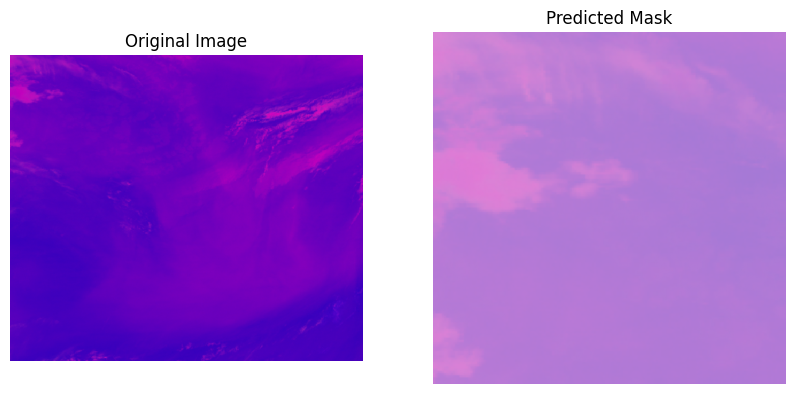

In [ ]:
import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt
import random

# ===== 1. Predict function =====
def predict_segmentation_keras(image_path, model, img_size=(160, 160)):
    # Load and preprocess image
    image = Image.open(image_path).convert("RGB")
    image_resized = image.resize(img_size)
    image_array = np.array(image_resized) / 255.0  # normalize to [0,1]
    image_tensor = np.expand_dims(image_array, axis=0)  # [1, H, W, 3]

    # Run prediction
    pred = model.predict(image_tensor)  # shape [1, H, W, 1] for binary
    mask = pred.squeeze()  # [H, W]

    # Threshold
    binary_mask = (mask > 0.5).astype(np.uint8)

    return image, binary_mask

# ===== 2. Visualization =====
def plot_segmentation(image, mask):
    plt.figure(figsize=(10, 5))

    # Original image
    plt.subplot(1, 2, 1)
    plt.title("Original Image")
    plt.imshow(image)
    plt.axis("off")

    # Mask overlay
    plt.subplot(1, 2, 2)
    plt.title("Predicted Mask")
    plt.imshow(image)
    plt.imshow(mask, alpha=0.5, cmap='Reds')
    plt.axis("off")

    plt.show()

# ===== 3. Run prediction =====
image_path = random.choice(test_input_img_paths)  # from your earlier split
image, mask = predict_segmentation_keras(image_path, model, img_size=(160, 160))
plot_segmentation(image, mask)
